# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: EMROVEVI

# Integrantes
* Vera Roux, LU: 326/25
* Emma Victoria Tripaldi, LU: 287/25
* María Rosario Cabrera, LU: 659/25
* Victoria Florencia Lima, LU: 101/25

In [1]:
import numpy as np
from alc import *
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import os

def buscar_ruta(*partes):
    """Busca un archivo por nombre en la carpeta actual y sus subcarpetas."""
    nombre = partes[-1]
    raices = [os.getcwd(), os.path.dirname(os.path.abspath("grupo_EMROVEVI_TP.ipynb"))]
    visitadas = set()
    for raiz in raices:
        raiz = os.path.abspath(raiz)
        if raiz in visitadas or not os.path.isdir(raiz):
            continue
        visitadas.add(raiz)
        for carpeta, _, archivos in os.walk(raiz):
            if nombre in archivos:
                return os.path.join(carpeta, nombre)
    raise FileNotFoundError(
        f"No se encontró {nombre!r}. Verifique que el archivo esté en la carpeta del notebook o en una subcarpeta."
    )


### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

**a)** Para $n$ puntos, el sistema de la ecuación (6) es $Q\,\mathbf{m}=\mathbf{0}$, con $Q\in\mathbb{R}^{2n\times 12}$ y $\mathbf{m}\in\mathbb{R}^{12}$ (las 12 entradas de $M\in\mathbb{R}^{3\times4}$). Cada punto aporta dos filas, una por cada coordenada de su pixel $(u_i,v_i)$.

**Rango necesario:** buscamos $\mathbf{m}\neq 0$, así que $\mathrm{Nu}(Q)\neq\{0\}$. Que la solución sea única a menos de un factor de escala significa que $\mathrm{Nu}(Q)$ es una recta, es decir $\dim\mathrm{Nu}(Q)=1$. Por el teorema de la dimensión:

$$\mathrm{rg}(Q)=12-\dim\mathrm{Nu}(Q)=12-1=11 .$$

**Cantidad mínima de puntos:** como $\mathrm{rg}(Q)\le 2n$, se necesita $2n\ge 11$, o sea $n\ge 5{,}5$. Por lo tanto hacen falta al menos $n=6$ puntos, que dan 12 ecuaciones para 11 grados de libertad (con 5 puntos hay solo 10 ecuaciones y $\dim\mathrm{Nu}(Q)\ge 2$).

**Condición sobre los puntos:** con $n=6$ la matriz $Q$ tiene 12 filas y debe tener rango 11, de modo que exista exactamente una dependencia lineal entre ellas (la que corresponde a $\mathbf{m}$). Esto se cumple si los puntos $P_i$ no son coplanares. 

Si todos los puntos son coplanares, se encuentran en el plano dado por $n_1X+n_2Y+n_3Z+d=0$.
Sea $\boldsymbol\pi=(n_1,n_2,n_3,d)^\top\neq0$ y $\tilde P_i=(X_i,Y_i,Z_i,1)^\top$. 
Entonces  $$\boldsymbol\pi^\top\tilde P_i=0\qquad\text{para todo } i .$$

Las filas de $Q$ para el punto $i$ son $[\tilde P_i^\top\ \ \mathbf 0^\top\ \ -u_i\tilde P_i^\top]$ y
$[\mathbf 0^\top\ \ \tilde P_i^\top\ \ -v_i\tilde P_i^\top]$. Para cualesquiera $a,b,c\in\mathbb{R}$, el vector
$\mathbf m=(a\boldsymbol\pi,\ b\boldsymbol\pi,\ c\boldsymbol\pi)$ da

$$(a-u_ic)\,\tilde P_i^\top\boldsymbol\pi=0,\qquad (b-v_ic)\,\tilde P_i^\top\boldsymbol\pi=0 ,$$

así que $Q\mathbf m=0$. Estos vectores forman un subespacio de dimensión **3** contenido en $\mathrm{Nu}(Q)$.
Es lo mismo que decir que aparecen 3 dependencias entre las columnas de $Q$: en cada bloque de 4 columnas,
$\pi_1q_1+\pi_2q_2+\pi_3q_3+\pi_4q_4=\mathbf 0$.

La solución verdadera $\mathbf m^\ast$ (una cámara, de rango 3) no está en ese subespacio, por lo tanto

$$\dim\mathrm{Nu}(Q)\ge 3+1=4\quad\Longrightarrow\quad \mathrm{rg}(Q)\le 12-4=8 .$$

Con puntos coplanares la solución deja de ser única: $M$ y $M+\mathbf w\boldsymbol\pi^\top$ ($\mathbf w\in\mathbb{R}^3$)
proyectan igual todos los puntos del plano. Por eso el caso coplanar se trabaja con la homografía $H$ (ejercicio 3).

Por último, decir que la solución es única "a menos de un factor de escala" significa que lo que queda determinado es la dirección $\langle\mathbf{m}\rangle$, no un vector particular: $\mathbf{m}$ y $c\,\mathbf{m}$ ($c\neq0$) representan la misma proyección, porque $\lambda$ es libre. 

**b)** Encontrar el vector m que resuelve la minimización de la ecuación 8

Con datos reales no existe $\mathbf{m}\neq 0$ con $Q\mathbf{m}=0$ exactamente, así que se resuelve

$$\min_{\|\mathbf{m}\|=1}\ \|Q\mathbf{m}\|^2 .$$

Desarrollando la norma:

$$\|Q\mathbf{m}\|^2=(Q\mathbf{m})^\top(Q\mathbf{m})=\mathbf{m}^\top Q^\top Q\,\mathbf{m}.$$

**Autovalores de $Q^\top Q$:** La matriz $Q^\top Q\in\mathbb{R}^{12\times12}$ es simétrica y semidefinida positiva ($\mathbf{x}^\top Q^\top Q\,\mathbf{x}=\|Q\mathbf{x}\|^2\ge0$). Por el teorema espectral tiene autovalores reales $0\le\lambda_1\le\lambda_2\le\dots\le\lambda_{12}$ y autovectores $\mathbf{v}_1,\dots,\mathbf{v}_{12}$ ortonormales, con $Q^\top Q\,\mathbf{v}_i=\lambda_i\mathbf{v}_i$.

**Escribimos $\mathbf{m}$ en esa base:** Como los $\mathbf{v}_i$ forman una base ortonormal de $\mathbb{R}^{12}$, existen escalares $c_i$ tales que

$$\mathbf{m}=\sum_{i=1}^{12}c_i\,\mathbf{v}_i,\qquad \|\mathbf{m}\|^2=1\ \Longrightarrow\ \sum_{i=1}^{12}c_i^2=1 .$$

Aplicando $Q^\top Q$:

$$Q^\top Q\,\mathbf{m}=\sum_i c_i\,Q^\top Q\,\mathbf{v}_i=\sum_i c_i\lambda_i\,\mathbf{v}_i,$$

y usando la ortonormalidad:

$$\|Q\mathbf{m}\|^2=\mathbf{m}^\top Q^\top Q\,\mathbf{m}=\sum_{i=1}^{12}\lambda_i\,c_i^2\ \ge\ \lambda_1\sum_{i=1}^{12}c_i^2=\lambda_1 .$$

**Conclusión:** La cota inferior $\lambda_1$ se alcanza con $c_1=\pm1$ y $c_i=0$ para $i>1$, es decir, con $\mathbf{m}=\pm\mathbf{v}_1$. Si $\lambda_1$ es un autovalor simple, ese es el único minimizador (salvo el signo).

Por lo tanto, **$\mathbf{m}$ es el autovector de norma 1 de $Q^\top Q$ asociado a su menor autovalor $\lambda_1$**. Si $Q=U\Sigma V^\top$ es una SVD, entonces $Q^\top Q=V\Sigma^2V^\top$, por lo que los autovalores de $Q^\top Q$ son $\sigma_i^2$ y $\mathbf{m}$ es la columna de $V$ asociada al menor valor singular $\sigma_{\min}$. El valor mínimo del residuo es $\|Q\mathbf{m}\|=\sigma_{\min}$, que vale 0 si los datos son exactos. El signo de $\mathbf{m}$ no está determinado, porque $\mathbf{m}$ y $-\mathbf{m}$ dan la misma proyección.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



**Factorización $K$, $R$.** 
De $M=K\,[R\mid t]$, el bloque izquierdo es $A=KR$, con $K$ triangular superior
(parámetros intrínsecos) y $R$ ortogonal. Para separarlos usamos la factorización QR de la inversa:

$$A^{-1}=(KR)^{-1}=R^\top K^{-1}=Q\,U,\qquad Q=R^\top,\quad U=K^{-1}.$$

$R^\top$ es ortogonal y $K^{-1}$ es triangular superior (la inversa de una triangular superior lo es),
así que la QR de $A^{-1}$ (calculada con Gram-Schmidt) los devuelve directamente:
$R=Q^\top$ y $K=U^{-1}$. Como Gram-Schmidt normaliza con normas positivas, $\mathrm{diag}(U)>0$ y por lo tanto
$\mathrm{diag}(K)>0$, lo que hace la descomposición única. La traslación sale de $K\,t=M_{[:,3]}$, por
sustitución hacia atrás, porque $K$ es triangular superior.


In [2]:
# a) Trabajamos con imágenes 1 y 50

det_corners = np.loadtxt(buscar_ruta("calib", "3d", "detected_corners.txt"))
imagen_1 = det_corners[0,:]
imagen_50 = det_corners[49,:]

# En la vida real tenemos un solo objeto, con 12 corners detectadas
real_corners = np.loadtxt(buscar_ruta("calib", "3d", "p_W_corners.txt"),delimiter=',')
objetos = real_corners

# Proceso para imagen 1
Q_imagen_1 = obtenerQ3d(imagen_1, real_corners)

# Proceso para imagen 50
Q_imagen_50 = obtenerQ3d(imagen_50, real_corners)

M_imagen_1 = resolverDLT3D(Q_imagen_1)
M_imagen_50 = resolverDLT3D(Q_imagen_50)

R_imagen_1, t_imagen_1, K_imagen_1 = devolverMatricesCalibracion3D(M_imagen_1)
R_imagen_50, t_imagen_50, K_imagen_50 = devolverMatricesCalibracion3D(M_imagen_50)

def det3(R):
    # determinante 3x3 como producto triple: r1 · (r2 × r3)
    return producto_interno(R[0], producto_vectorial(R[1], R[2]))

def ajustar_calibracion(R, t, K):
    K = K / K[2][2]                 # K sale salvo escala: la fijamos con K[2][2] = 1
    if det3(R) < 0:                 # det = −1 es una reflexión, no una rotación
        R, t = -R, -t              # M y −M proyectan igual: cambiamos el signo de la solución
    return R, t, K

R_imagen_1,  t_imagen_1,  K_imagen_1  = ajustar_calibracion(R_imagen_1,  t_imagen_1,  K_imagen_1)
R_imagen_50, t_imagen_50, K_imagen_50 = ajustar_calibracion(R_imagen_50, t_imagen_50, K_imagen_50)

print("Imagen 1  | det R =", det3(R_imagen_1),  "| K[2][2] =", K_imagen_1[2][2])
print("Imagen 50 | det R =", det3(R_imagen_50), "| K[2][2] =", K_imagen_50[2][2])

print("Imagen 1")
print("R:",R_imagen_1)
print("t:",t_imagen_1)
print("K:",K_imagen_1)

print("Imagen 50")
print("R:",R_imagen_50)
print("t:",t_imagen_50)
print("K:",K_imagen_50)

Imagen 1  | det R = 0.9999999999999998 | K[2][2] = 1.0
Imagen 50 | det R = 0.9999999999999999 | K[2][2] = 1.0
Imagen 1
R: [[ 0.618213    0.12921397 -0.77531699]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494017  0.61829533]]
t: [-18.1679383  -14.50326884  40.59128922]
K: [[ 4.25859863e+02 -1.56351666e-02  3.54418499e+02]
 [ 0.00000000e+00  4.24565307e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Imagen 50
R: [[ 0.55592054  0.11320882 -0.8234902 ]
 [-0.3284675   0.93997304 -0.09251913]
 [ 0.76358461  0.32192305  0.55973574]]
t: [-18.7079249  -13.75968616  41.96162272]
K: [[435.32258198  -1.70546123 355.2225843 ]
 [  0.         433.72737289 249.18720148]
 [  0.           0.           1.        ]]


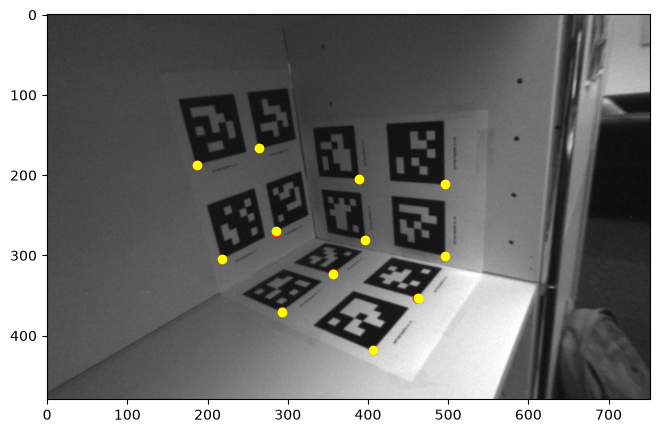

In [19]:
# Graficamos las esquinas detectadas de la imagen 1 para ver si nos dieron bien las coordenadas

img_1 = cv2.imread(buscar_ruta("img_0001.jpg"))
img_1 = img_1[:,:,::-1]
plt.figure(figsize=(8,5))
plt.imshow(img_1)

# Reproyectamos los puntos del objeto para ver que coincidan con los originales

ptos_reproyectados = []

for pto in real_corners:
    pto_cam = calcularAx(R_imagen_1, pto) + t_imagen_1       # R·X + t
    pto_aux = calcularAx(K_imagen_1, pto_cam)                # K·(R·X + t)
    pto_reproyectado = pto_aux/pto_aux[2]
    ptos_reproyectados += [pto_reproyectado]

ptos_reproyectados = np.array(ptos_reproyectados)

plt.scatter(imagen_1[0::2], imagen_1[1::2],c='r')
plt.scatter(ptos_reproyectados[:,0],ptos_reproyectados[:,1],c='yellow') 
plt.show()

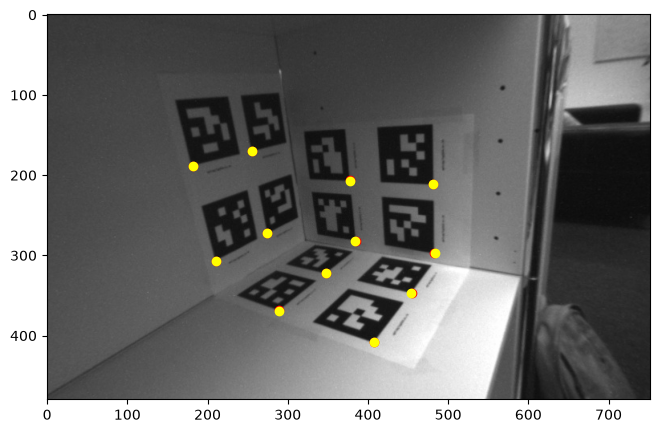

In [20]:
# Graficamos las esquinas detectadas de la imagen 50 para ver si nos dieron bien las coordenadas

img_50 = cv2.imread(buscar_ruta("img_0050.jpg"))
img_50 = img_50[:,:,::-1]
plt.figure(figsize=(8,5))
plt.imshow(img_50)

# Reproyectamos los puntos del objeto para ver que coincidan con los originales

ptos_reproyectados = []

for pto in real_corners:
    pto_cam = calcularAx(R_imagen_50, pto) + t_imagen_50
    pto_aux = calcularAx(K_imagen_50, pto_cam)
    pto_reproyectado = pto_aux/pto_aux[2]
    ptos_reproyectados += [pto_reproyectado]

ptos_reproyectados = np.array(ptos_reproyectados)

plt.scatter(imagen_50[0::2], imagen_50[1::2],c='r')
plt.scatter(ptos_reproyectados[:,0],ptos_reproyectados[:,1],c='yellow') 
plt.show()

In [5]:
# b) Ahora le pasamos el sesgo 2, αu = αv

R_imagen_1_s2, t_imagen_1_s2, K_imagen_1_s2 = devolverMatricesCalibracion3D(M_imagen_1, sesgo2=True)
R_imagen_50_s2, t_imagen_50_s2, K_imagen_50_s2 = devolverMatricesCalibracion3D(M_imagen_50, sesgo2=True)

# Normalizamos K (K[2][2] = 1) y verificamos que R sea una rotación (det = +1)
R_imagen_1_s2,  t_imagen_1_s2,  K_imagen_1_s2  = ajustar_calibracion(R_imagen_1_s2,  t_imagen_1_s2,  K_imagen_1_s2)
R_imagen_50_s2, t_imagen_50_s2, K_imagen_50_s2 = ajustar_calibracion(R_imagen_50_s2, t_imagen_50_s2, K_imagen_50_s2)


print("Imagen 1 con sesgo 2")
print("R:",R_imagen_1_s2)
print("t:",t_imagen_1_s2)
print("K:",K_imagen_1_s2)

print("Imagen 50 con sesgo 2")
print("R:",R_imagen_50_s2)
print("t:",t_imagen_50_s2)
print("K:",K_imagen_50_s2)

Imagen 1 con sesgo 2
R: [[ 0.618213    0.12921397 -0.77531699]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494017  0.61829533]]
t: [-18.16793668 -14.45918089  40.59128922]
K: [[ 4.25859863e+02 -1.56351666e-02  3.54418499e+02]
 [ 0.00000000e+00  4.25859863e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Imagen 50 con sesgo 2
R: [[ 0.55592054  0.11320882 -0.8234902 ]
 [-0.3284675   0.93997304 -0.09251913]
 [ 0.76358461  0.32192305  0.55973574]]
t: [-18.70772737 -13.70926476  41.96162272]
K: [[435.32258198  -1.70546123 355.2225843 ]
 [  0.         435.32258198 249.18720148]
 [  0.           0.           1.        ]]


In [6]:
# c) Ahora le pasamos el sesgo 1, K[0][1] = 0

R_imagen_1_s1, t_imagen_1_s1, K_imagen_1_s1 = devolverMatricesCalibracion3D(M_imagen_1, sesgo1=True)
R_imagen_50_s1, t_imagen_50_s1, K_imagen_50_s1 = devolverMatricesCalibracion3D(M_imagen_50, sesgo1=True)

R_imagen_1_s1,  t_imagen_1_s1,  K_imagen_1_s1  = ajustar_calibracion(R_imagen_1_s1,  t_imagen_1_s1,  K_imagen_1_s1)
R_imagen_50_s1, t_imagen_50_s1, K_imagen_50_s1 = ajustar_calibracion(R_imagen_50_s1, t_imagen_50_s1, K_imagen_50_s1)


print("Imagen 1 con sesgo 1")
print("R:",R_imagen_1_s1)
print("t:",t_imagen_1_s1)
print("K:",K_imagen_1_s1)

print("Imagen 50 con sesgo 1")
print("R:",R_imagen_50_s1)
print("t:",t_imagen_50_s1)
print("K:",K_imagen_50_s1)

Imagen 1 con sesgo 1
R: [[ 0.618213    0.12921397 -0.77531699]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494017  0.61829533]]
t: [-18.16740582 -14.50326884  40.59128922]
K: [[425.85986276   0.         354.41849862]
 [  0.         424.56530722 256.85335511]
 [  0.           0.           1.        ]]
Imagen 50 con sesgo 1
R: [[ 0.55592054  0.11320882 -0.8234902 ]
 [-0.3284675   0.93997304 -0.09251913]
 [ 0.76358461  0.32192305  0.55973574]]
t: [-18.65401864 -13.75968616  41.96162272]
K: [[435.32258198   0.         355.2225843 ]
 [  0.         433.72737289 249.18720148]
 [  0.           0.           1.        ]]


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

**a)** Para $n$ puntos, el sistema de la ecuación (11) es $Q\,\mathbf{h}=\mathbf{0}$, con $Q\in\mathbb{R}^{2n\times 9}$ y $\mathbf{h}\in\mathbb{R}^{9}$ (las 9 entradas de $H$).

Buscamos una solución no nula, así que $\mathrm{Nu}(Q)\neq\{\mathbf{0}\}$. Que sea única a menos de un factor de escala significa que $\dim\mathrm{Nu}(Q)=1$.

Por el teorema de la dimensión:

$$\mathrm{rg}(Q)=9-\dim\mathrm{Nu}(Q)=9-1=\mathbf{8}.$$


In [7]:
# Obtenemos las 77 esquinas (u,v) de las 20 imágenes

ruta = buscar_ruta("calib", "coplanar", "coordenadas_esquinas.csv")
coordenadas_esquinas_ajedrez = pd.read_csv(ruta)
imgPts_ajedrez = np.array(coordenadas_esquinas_ajedrez)


patron = (11, 7)
square_size = 3.0

# Calculamos los U,V para cada una de las esquinas

objPts_ajedrez = []

for fila in range(patron[1]):       # 7 filas
    for columna in range(patron[0]):  # 11 columnas
        U = columna * square_size
        V = fila * square_size
        W = 0.0

        objPts_ajedrez.append([U, V, W])

objPts_ajedrez = np.array(objPts_ajedrez)

Hlst_ajedrez = []

k=0
# Como hay 77 esquinas por tablero y 20 imágenes, en total hay 1540 esquinas
# Saltamos de a 77 para pasar de una imagen a otra
while(k<1540): 

    aux = imgPts_ajedrez[k:k+77,2:4]
    aux = np.array(aux)
    
    Q_imagen_i = obtenerQ2d(aux, objPts_ajedrez)
    Hlst_ajedrez += [obtener_H(Q_imagen_i)]
    
    k +=77

A_ajedrez = armarA(Hlst_ajedrez)

K_ajedrez = calcularMatrizK2D(A_ajedrez)
print("K obtenida")
print(K_ajedrez)

K obtenida
[[733.65280893   0.         516.02770403]
 [  0.         744.50175601 295.96553416]
 [  0.           0.           1.        ]]


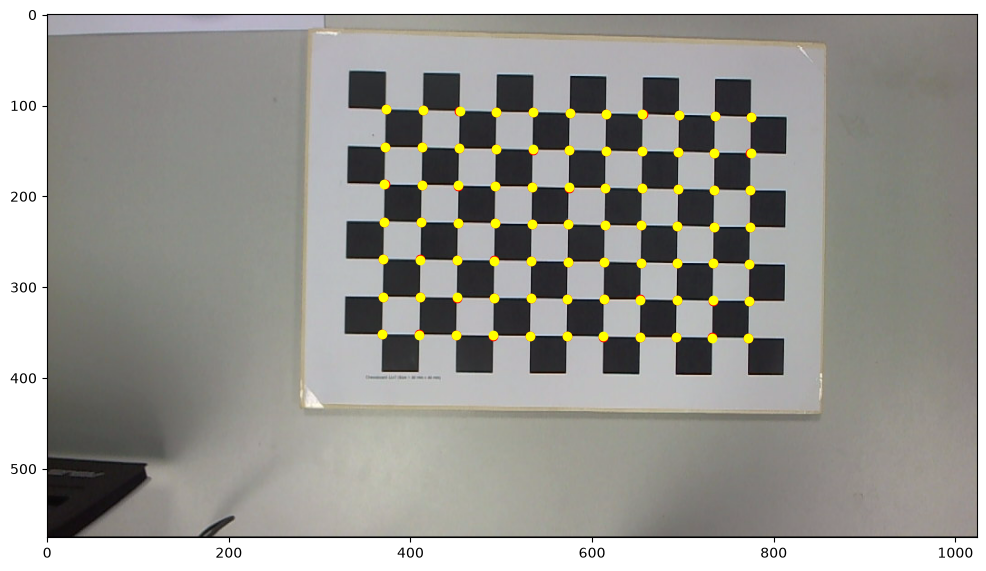

In [8]:
# Graficamos los puntos de una imagen para ver si nos dieron bien las coordenadas

img_1 = cv2.imread(buscar_ruta("calib", "coplanar", "Im_R_1.png"))
img_1 = img_1[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img_1)

# Reproyectamos los puntos para ver que coincidan con los originales

ptos_reproyectados = []

for pto in objPts_ajedrez:
    pto = np.array([pto[0],pto[1],1])
    pto_aux = calcularAx(Hlst_ajedrez[0], pto)
    pto_reproyectado = pto_aux/pto_aux[2]
    ptos_reproyectados += [pto_reproyectado]

ptos_reproyectados = np.array(ptos_reproyectados)

plt.scatter(imgPts_ajedrez[:77, 2], imgPts_ajedrez[:77,3],c='r')
plt.scatter(ptos_reproyectados[:,0],ptos_reproyectados[:,1],c='yellow') 
plt.show()

In [9]:
# Encontramos la pose de la imagen 1

Q_im_1 = obtenerQ2d(imgPts_ajedrez[0:77,2:4], objPts_ajedrez)
H_im_1 = obtener_H(Q_im_1)
R_im_1, t_im_1 = obtenerPose2D(H_im_1, K_ajedrez)
print("Pose imagen 1") 
print(R_im_1, t_im_1)

# Encontramos la pose de la imagen 10

Q_im_10 = obtenerQ2d(imgPts_ajedrez[693:770,2:4], objPts_ajedrez)
H_im_10 = obtener_H(Q_im_10)
R_im_10, t_im_10 = obtenerPose2D(H_im_10, K_ajedrez)
print("Pose imagen 10")
print(R_im_10, t_im_10)

# Encontramos la pose de la imagen 20

Q_im_20 = obtenerQ2d(imgPts_ajedrez[1463:1540,2:4], objPts_ajedrez)
H_im_20 = obtener_H(Q_im_20)
R_im_20, t_im_20 = obtenerPose2D(H_im_20, K_ajedrez)
print("Pose imagen 20")
print(R_im_20, t_im_20)


Pose imagen 1
[[-0.99955514  0.01398846 -0.02730259]
 [-0.01219915 -0.99957233  0.00767909]
 [-0.02721586  0.00806339  0.99929831]] [ 10.58565802  13.94794188 -54.17247516]
Pose imagen 10
[[-0.99739793 -0.06637746 -0.02468869]
 [ 0.06309699 -0.98504523  0.15505988]
 [-0.03487311  0.15314358  0.98667029]] [  9.31055077  15.2140836  -53.24975063]
Pose imagen 20
[[ 0.99018938  0.02566728 -0.13717902]
 [-0.03822679  0.9956112  -0.08378142]
 [ 0.13440128  0.0880954   0.98682482]] [ -8.07368579 -14.467364    48.13549651]


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

**Elección de los puntos de la cancha.** Para calcular la homografía $H$ entre el plano de la cancha y
la imagen usamos 5 puntos con coordenadas conocidas (en metros, $X$ a lo largo de la línea de gol, $Y$ la distancia a esa línea):

| Punto | $(X,Y)$ |
|---|---|
| Punto penal | $(34,\ 11)$ |
| Esquina izquierda del área chica | $(24{,}84,\ 5{,}5)$ |
| Esquina derecha del área chica | $(43{,}16,\ 5{,}5)$ |
| Poste izquierdo | $(30{,}34,\ 0)$ |
| Poste derecho | $(37{,}66,\ 0)$ |

Los puntos cumplen las características que pide el método:

1. **Son coplanares.** Todos están sobre el piso de la cancha, es decir, sobre el plano $Z=0$. Esto es necesario porque la proyección de un plano a la imagen es una homografía $\lambda\tilde m=H\tilde P$ con $\tilde P=(X,Y,1)^\top$ (eq.(10) del enunciado). Un punto fuera del plano, como la cabeza de un jugador, no cumple esa relación y se ubicaría mal.

2. **No hay tres colineales.** $H$ tiene 8 grados de libertad (números independientes a determinar) y cada punto aporta 2 ecuaciones, por lo que hacen falta al menos 4 puntos. Si tres estuvieran sobre una recta, el tercero no agregaría información: el rango de $Q$ bajaría de 8 a 7 y $H$ no quedaría determinada.

3. **Tienen coordenadas reales conocidas**, porque las medidas del área chica ($18{,}32\times5{,}5$ m), del arco ($7{,}32$ m) y del punto penal ($11$ m) son reglamentarias, y se identifican con precisión en la imagen (esquinas, cruces de líneas y postes).

4. **Están repartidos** a lo ancho del arco y en tres distancias distintas a la línea de gol ($Y=0,\ 5{,}5,\ 11$), lo que mejora el condicionamiento de $Q$.

Usamos 5 puntos (uno más que el mínimo) para que el ajuste mediante mínimos cuadrados reduzca el efecto del error de los clicks que hicimos nosotras.

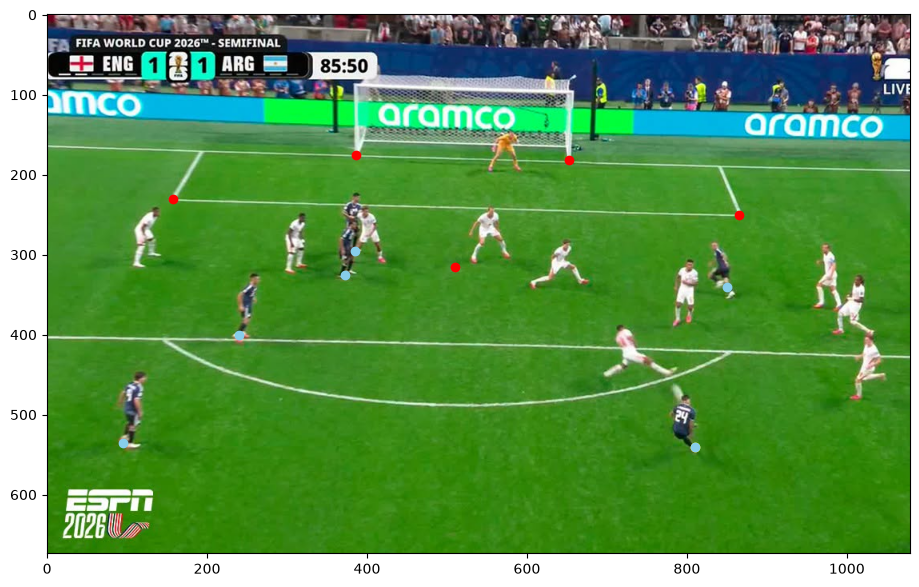

In [10]:
# a) 

# Ubicamos los puntos

img = cv2.imread(buscar_ruta("futbol", "test-gol-enzo.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

#Pto penal, area chica izquierda, area chica derecha, poste izquierdo, poste derecho

puntos_img_cancha = np.array([[510,315],[157,230],[865,250],[386,175],[652,182]])
puntos_obj_cancha = np.array([[34,11],[24.84,5.5],[43.16,5.5],[30.34,0],[37.66,0]])
punto_enzo = np.array([810,540,1])

#Julian, Lautaro, Tagliafico, Cuti, McAllister

pies_argentinos = np.array([[95,535],[240,400],[372,325],[385,295],[850,340],[810,540]])

# Graficamos los pixeles calculados

plt.scatter(puntos_img_cancha[:,0], puntos_img_cancha[:,1],c='r')
plt.scatter(punto_enzo[0],punto_enzo[1],c='yellow') #punto enzo
plt.scatter(pies_argentinos[:,0],pies_argentinos[:,1],c='skyblue')
plt.show()

In [11]:
# Buscamos la posicion de Enzo en la cancha a partir de su posicion en la imagen y H inversa

Q_enzo = obtenerQ2d(puntos_img_cancha,puntos_obj_cancha)
H_enzo = obtener_H(Q_enzo)
H_enzo_inversa = inversa(H_enzo)

pos_enzo_aux = calcularAx(H_enzo_inversa, punto_enzo)

#Como obtener_H te devuelve un vector escalado, dividimos por lambda para que la ultima coordenada quede 1

pos_enzo = pos_enzo_aux / pos_enzo_aux[2]

print("Distancia de Enzo al arco en metros")
print(pos_enzo[1])

Distancia de Enzo al arco en metros
23.90000794855541


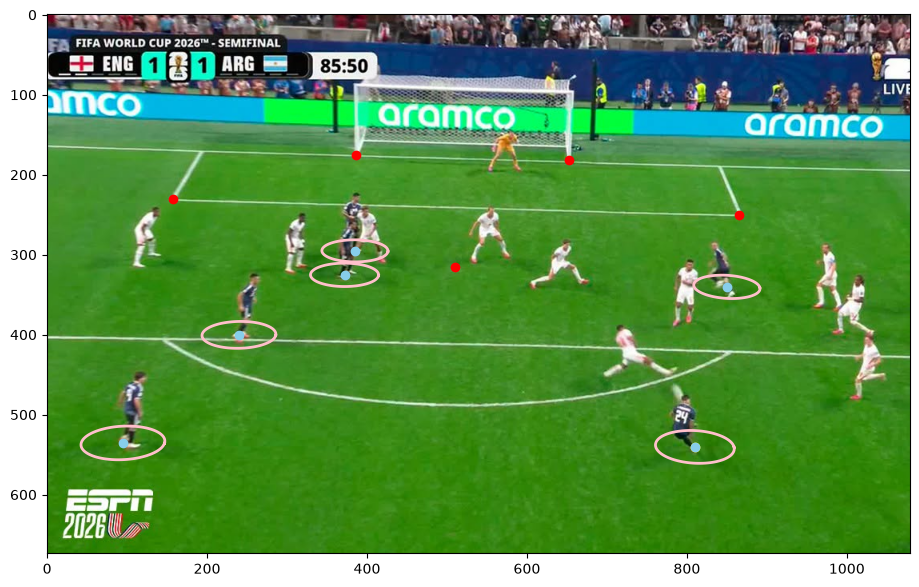

In [12]:
# Graficamos los círculos alrededor de los jugadores

img = cv2.imread(buscar_ruta("futbol", "test-gol-enzo.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

for jugador in pies_argentinos:
    pos_jugador = np.array([jugador[0],jugador[1],1])
    pies_argentinos_aux = calcularAx(H_enzo_inversa,pos_jugador)
    pie_argentino_obj = pies_argentinos_aux / pies_argentinos_aux[2]

    centro_circulo = (pie_argentino_obj[0], pie_argentino_obj[1])

    puntos_circulo = circulo_de_obj_a_img(H_enzo, centro_circulo)
    plt.plot(puntos_circulo[:,0], puntos_circulo[:,1],c='pink', linewidth=2)


plt.scatter(puntos_img_cancha[:,0], puntos_img_cancha[:,1],c='r')
plt.scatter(punto_enzo[0],punto_enzo[1],c='yellow') #punto enzo
plt.scatter(pies_argentinos[:,0],pies_argentinos[:,1],c='skyblue')
plt.show()

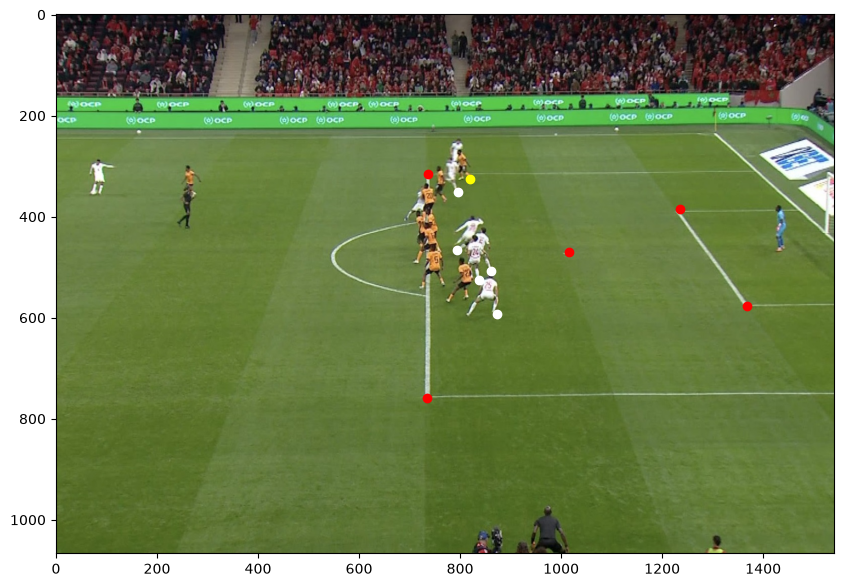

In [13]:
# b)
# Ubicamos los puntos de la cancha en la imagen del offside

img = cv2.imread(buscar_ruta("futbol", "test-fuera-de-juego.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

#area grande derecha, area grande izquierda, Punto penal, area chica derecha, area chica izquierda
puntos_img_offside = np.array([[734,758],[736,315],[1015,470],[1368,577],[1235,385]])
puntos_obj_offside = np.array([[54.16,16.5],[13.84,16.5],[34,11],[43.16,5.5],[24.84,5.5]])
punto_defensor = [820,325,1]

# atacantes
puntos_atacantes = np.array([[796, 351, 1], [861, 508, 1], [793, 466, 1], [838, 525, 1], [874, 593, 1]])

plt.scatter(puntos_img_offside[:,0], puntos_img_offside[:,1],c='r')
plt.scatter(punto_defensor[0],punto_defensor[1],c='yellow') 
plt.scatter(puntos_atacantes[:,0],puntos_atacantes[:,1],c='white')
plt.show()

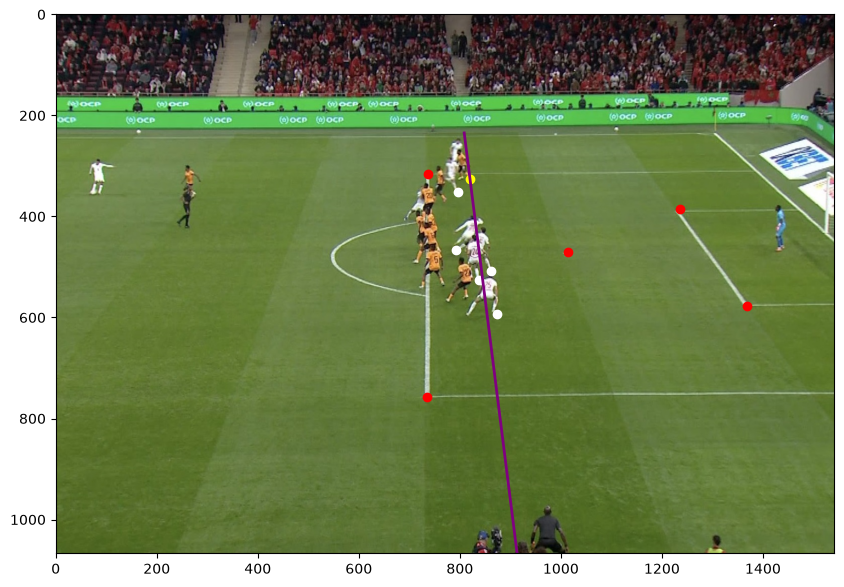

Jugador 1: U = 15.09 m, dif = -0.64 m, offside: no
Jugador 2: U = 14.11 m, dif = +0.34 m, offside: sí
Jugador 3: U = 15.35 m, dif = -0.89 m, offside: no
Jugador 4: U = 14.59 m, dif = -0.13 m, offside: no
Jugador 5: U = 14.10 m, dif = +0.35 m, offside: sí


In [14]:
Q_offside = obtenerQ2d(puntos_img_offside,puntos_obj_offside)
H_offside = obtener_H(Q_offside)
H_offside_inversa = inversa(H_offside)
pos_defensor_aux = calcularAx(H_offside_inversa, punto_defensor) #en el estadio azteca

#Como obtener_H te devuelve un vector escalado, dividimos por lambda para que la ultima coordenada quede 1
pos_defensor = pos_defensor_aux / pos_defensor_aux[2]

#Estamos en el estadio azteca
V_defensor, U_defensor = pos_defensor[0]/pos_defensor[2], pos_defensor[1]/pos_defensor[2]
extremos_obj = [np.array([0,U_defensor,1]),np.array([68,U_defensor,1])]

#Pasamos a la img
extremos_img = []

for extremo in extremos_obj:
    X = calcularAx(H_offside, extremo)
    X =  X/X[2]

    extremos_img += [[X[0],X[1]]]
    
extremos_img = np.array(extremos_img)

img = cv2.imread(buscar_ruta("futbol", "test-fuera-de-juego.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)
plt.plot(extremos_img[:,0],extremos_img[:,1],c='purple',linewidth=2)
plt.scatter(puntos_img_offside[:,0], puntos_img_offside[:,1],c='r')
plt.scatter(punto_defensor[0],punto_defensor[1],c='yellow') 
plt.scatter(puntos_atacantes[:,0],puntos_atacantes[:,1],c='white')
plt.xlim(0,img.shape[1])
plt.ylim(img.shape[0],0)
plt.show()

es_offside = []
for i, p in enumerate(puntos_atacantes, 1):
    pos = calcularAx(H_offside_inversa, p)
    pos = pos / pos[2]
    U_atac = pos[1]                      # distancia a la línea de fondo (m)
    dif = U_defensor - U_atac                 # > 0: más cerca de la línea de fondo que el defensor
    es_offside.append(dif > 0)
    print(f"Jugador {i}: U = {U_atac:.2f} m, dif = {dif:+.2f} m, offside: {'sí' if dif > 0 else 'no'}")

**Análisis.** Pasamos el punto de apoyo de cada jugador a coordenadas de la cancha con $H^{-1}$
y comparamos su distancia a la línea de gol ($Y$, en metros) con la del penúltimo defensor. 
Un atacante está en posición de offside si $U_{atac}<U_{defensor}$.

**Puntos usados.** Todos están sobre el piso: los 5 de referencia (esquinas del área grande y
del área chica, punto penal) y los pies de los jugadores. Con la cabeza o el torso no valdría,
porque están fuera del plano y $H^{-1}$ los ubicaría más lejos de lo que están.
Además, no hay tres colineales.

| Jugador | $U$ (m) | dif. con la línea (m) | ¿Offside? |
|---|---|---|---|
| 1 | 15.09 m | -0.64 m | no |
| 2 | 14.11 m | +0.34 m | sí |
| 3 | 15.35 m | -0.89 m | no |
| 4 | 14.59 m | -0.13 m | no |
| 5 | 14.10 m | +0.35 m | sí |

Hay dos jugadores en offside.

**Limitaciones.** Cada click tiene un error de unos píxeles. Si la diferencia con la línea es
menor que ese error, la decisión es inconclusa. Además usamos los pies, pero en el
reglamento cuenta cualquier parte del cuerpo con la que se puede jugar la pelota. Por último, algunos pies no se llegan a distinguir del todo, hicimos un click aproximado.

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

* Vamos a realizar el ejercicio utilizando las funciones de puntos coplanares a pesar de que en los puntos originales hay una leve variación en Z de 0,1 m, lo que resulta insignificante con respecto a las grandes magnitudes con las que trabajamos. 

* Si quisieramos hacer Q3D con los 5 puntos dados en el CSV, tendríamos 10 filas y 12 columnas. El rango sería 11, necesitaríamos al menos 6 puntos no coplanares, pero tenemos 5. Luego nos inclinamos por la opción de Q2D despreciando la coordenada Z.


In [ ]:
# a)

salguero_csv = pd.read_csv(buscar_ruta("salguero", "world_img_pts.csv"), sep=";")
salguero_array = salguero_csv.to_numpy(dtype=float)

objPts_salguero2d = np.zeros((5,2))
img1Pts_salguero2d = np.zeros((5,2))
img2Pts_salguero2d = np.zeros((5,2))
img3Pts_salguero2d = np.zeros((5,2))
img4Pts_salguero2d = np.zeros((5,2))

for i in range(np.shape(salguero_array)[0]):
    for j in range(1,3):
        objPts_salguero2d[i][j-1] = salguero_array[i][j]

        img1Pts_salguero2d[i][0] = salguero_array[i][4]
        img1Pts_salguero2d[i][1] = salguero_array[i][5]
        img2Pts_salguero2d[i][0] = salguero_array[i][6]
        img2Pts_salguero2d[i][1] = salguero_array[i][7]
        img3Pts_salguero2d[i][0] = salguero_array[i][8]
        img3Pts_salguero2d[i][1] = salguero_array[i][9]
        img4Pts_salguero2d[i][0] = salguero_array[i][10]
        img4Pts_salguero2d[i][1] = salguero_array[i][11]
        
# El DLT2D queda mal condicionado y por eso la normalización isotrópica lo arregla sin cambiar la homografía
# Esto lo hace trasladando el centro de los puntos al origen y escalando para que la distancia media al origen sea raíz de 2
# Normalizamos para que las columnas de Q tengan escalas comparables y el DLT2D quede bien condicionado

H1_salguero2d = obtener_H_normalizada(img1Pts_salguero2d, objPts_salguero2d)
H2_salguero2d = obtener_H_normalizada(img2Pts_salguero2d, objPts_salguero2d)
H3_salguero2d = obtener_H_normalizada(img3Pts_salguero2d, objPts_salguero2d)
H4_salguero2d = obtener_H_normalizada(img4Pts_salguero2d, objPts_salguero2d)

Hlst_salguero = [H1_salguero2d, H2_salguero2d, H3_salguero2d, H4_salguero2d]
A_salguero = armarA(Hlst_salguero)

# Centro de la imagen, para comparar
img = cv2.imread(buscar_ruta("salguero", "img_10_18_47_351.jpg"))
u0, v0 = img.shape[1]/2, img.shape[0]/2

# Primer intento: método general (Zhang items f y g), sin imponer nada sobre K

B_libre = obtener_B(A_salguero, sesgo1=False)
L_libre = calculaCholesky(B_libre)                    # B = L·Lt, con L = K^(-T)
K_libre = trasponer(inversa(L_libre))
K_libre = K_libre / K_libre[2][2]

print("K sin restricciones:")
print(K_libre)
print("\n αu/αv =", K_libre[0][0]/K_libre[1][1], "   (con píxeles cuadrados esperamos ≈ 1)")
print("γ/αu  =", K_libre[0][1]/K_libre[0][0], "   (esperamos ≈ 0)")
print("(u0, v0) obtenido:", K_libre[0][2], K_libre[1][2], "  vs centro de la imagen:", u0, v0, "\n")


# Segundo intento: si en cambio forzamos γ = 0 sobre B (sesgo1=True), B deja de ser definida positiva

B_sesgo1 = obtener_B(A_salguero, sesgo1=True)
menor1 = B_sesgo1[0][0]
menor2 = B_sesgo1[0][0]*B_sesgo1[1][1] - B_sesgo1[0][1]*B_sesgo1[1][0]
menor3 = producto_interno(B_sesgo1[0], producto_vectorial(B_sesgo1[1], B_sesgo1[2]))
print("Menores principales con sesgo1=True:", menor1, menor2, menor3, "\n(hay negativos: no existe Cholesky)")
# K_sesgo1 = calcularMatrizK2D(A_salguero)   # falla por lo anterior

K sin restricciones:
[[2.75558841e+03 1.22015962e+03 2.33866468e+02]
 [0.00000000e+00 1.92678406e+02 1.98547736e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

 αu/αv = 14.301490623098623    (con píxeles cuadrados esperamos ≈ 1)
γ/αu  = 0.44279458375403685    (esperamos ≈ 0)
(u0, v0) obtenido: 233.86646770022116 198.54773566466022   vs centro de la imagen: 800.0 600.0 

Menores principales con sesgo1=True: 1.1603127805219577e-05 -7.437191552947805e-08 -8.613262077707179e-06 
(hay negativos: no existe Cholesky)


**Primer intento: $K$ sin restricciones.** Resolvimos $b$ como el menor vector singular de $A$ (Zhang,
item f) y recuperamos $K$ con Cholesky (item g). Se obtiene

$$K\approx\begin{pmatrix}2756&1220&234\\0&193&199\\0&0&1\end{pmatrix},$$

que **no es físicamente plausible**:

| Parámetro | Obtenido | Esperado |
|---|---|---|
| $\alpha_u/\alpha_v$ | $\approx 14{,}3$ | $\approx 1$ (píxeles cuadrados) |
| $\gamma/\alpha_u$ | $\approx 0{,}44$ | $\approx 0$ |
| $(u_0,v_0)$ | $(234,\ 199)$ | $(800,\ 600)$, el centro de la imagen |

Intentamos corregirlo forzando $\gamma=0$ sobre $B$ (poniendo $B_{12}=0$ después de resolver), pero así $B$
**deja de ser definida positiva** (dos de sus menores principales son negativos) y no existe la
factorización de Cholesky. Con solo 4 vistas y 5 parámetros libres el problema está mal condicionado y
no se puede corregir "a mano" sobre $B$.

Por eso, en la celda siguiente imponemos las hipótesis sobre $K$ **antes** de resolver, es decir, la
parametrizamos con una sola incógnita, $f$.

### Cálculo de la focal $f$: sistema que resuelve `calcular_f`

**Hipótesis sobre $K$.** Suponemos píxeles cuadrados ($\alpha_u=\alpha_v=f$, porque $\alpha_u=f\,k_u$ y
$\alpha_v=f\,k_v$ con $k_u=k_v$), sin sesgo ($\gamma=0$) y punto principal $(u_0,v_0)$ en el centro de la
imagen, que conocemos. Entonces

$$K=\begin{pmatrix} f&0&u_0\\ 0&f&v_0\\ 0&0&1\end{pmatrix},$$

y la única incógnita es $f$ (en píxeles).

**Base teórica (Zhang, sección 2.2).** Cada vista $j$ del plano da una homografía $H_j=[c_1\ c_2\ c_3]\sim K\,[r_1\ r_2\ t]$
(ec. 10 y 12). Como $r_1$ y $r_2$ son ortonormales, con $B=K^{-\top}K^{-1}$ se cumple (ec. 13)

$$c_1^\top B\,c_2=0,\qquad c_1^\top B\,c_1-c_2^\top B\,c_2=0 .$$

Con $b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})^\top$ se tiene $c_i^\top B\,c_j=v_{ij}^\top b$, donde

$$v_{ij}=\big(h_{1i}h_{1j},\ h_{1i}h_{2j}+h_{2i}h_{1j},\ h_{2i}h_{2j},\ h_{3i}h_{1j}+h_{1i}h_{3j},\ h_{3i}h_{2j}+h_{2i}h_{3j},\ h_{3i}h_{3j}\big).$$

Cada vista aporta dos filas, $v_{12}^\top$ y $(v_{11}-v_{22})^\top$, y con las 4 vistas `armarA` construye
$A\in\mathbb{R}^{8\times 6}$ con $A\,b=0$.

**$B$ en función de $f$.** Con $K^{-1}=\begin{pmatrix}1/f&0&-u_0/f\\0&1/f&-v_0/f\\0&0&1\end{pmatrix}$:

$$B=K^{-\top}K^{-1}=\begin{pmatrix}\frac1{f^2}&0&-\frac{u_0}{f^2}\\[2pt]0&\frac1{f^2}&-\frac{v_0}{f^2}\\[2pt]-\frac{u_0}{f^2}&-\frac{v_0}{f^2}&\frac{u_0^2+v_0^2}{f^2}+1\end{pmatrix}.$$

Llamando $x=1/f^2$:

$$b=x\,(1,\ 0,\ 1,\ -u_0,\ -v_0,\ u_0^2+v_0^2)^\top+(0,0,0,0,0,1)^\top .$$

**Sistema.** Al reemplazar en $A\,b$ queda una ecuación **lineal en $x$** (llamamos a1 a lo que acompaña a la x y a0 a lo que no):

$$A\,b=x\,a_1+a_0=0,$$

con $a_0$ la columna 6 de $A$ (en el código `A[:,5]`) y

$$a_1=A_{[:,1]}+A_{[:,3]}-u_0A_{[:,4]}-v_0A_{[:,5]}+(u_0^2+v_0^2)A_{[:,6]}$$

(en el código, columnas $0,2,3,4,5$). La columna 2 no aparece porque $B_{12}=0$.
Fila por fila, son **8 ecuaciones con una sola incógnita**:

$$p_i\,x+q_i=0,\qquad i=1,\dots,8,\qquad p_i=(a_1)_i,\ \ q_i=(a_0)_i .$$

**Cuadrados mínimos.** Por el ruido, las 8 ecuaciones no se cumplen exactamente. Elegimos el $x$ que
minimiza el error cuadrático total:

$$E(x)=\sum_{i=1}^{8}(p_i x+q_i)^2 .$$

$E$ es una parábola con mínimo. Derivando e igualando a cero:

$$E'(x)=2\sum p_i(p_ix+q_i)=0\ \Longrightarrow\ x=-\frac{\sum_i p_iq_i}{\sum_i p_i^2}=-\frac{a_0\cdot a_1}{a_1\cdot a_1}.$$

Finalmente $f=1/\sqrt{x}$. Si $x\le 0$ no existe una distnacia focal real y la función devuelve `None`.

**Por qué esta restricción.** Sin imponerla, $b$ tiene 5 grados de libertad
(los 5 parámetros de $K$) y el sistema resuelto con solo 4 vistas resultó mal condicionado: los parámetros
obtenidos no eran plausibles (por ejemplo, $\alpha_u$ y $\alpha_v$ muy distintos). 

In [22]:

# El DLT2D queda mal condicionado y por eso la normalización isotrópica lo arregla sin cambiar la homografía
# Esto lo hace trasladando el centro de los puntos al orígen y escalando para que la distancia media al orígen sea raíz de 2
# Normalizamos para que las columnas de Q tengan escalas comparables y el DLT2D quede bien condicionado

H1_salguero2d = obtener_H_normalizada(img1Pts_salguero2d, objPts_salguero2d)
H2_salguero2d = obtener_H_normalizada(img2Pts_salguero2d, objPts_salguero2d)
H3_salguero2d = obtener_H_normalizada(img3Pts_salguero2d, objPts_salguero2d)
H4_salguero2d = obtener_H_normalizada(img4Pts_salguero2d, objPts_salguero2d)

Hlst_salguero = [H1_salguero2d, H2_salguero2d, H3_salguero2d, H4_salguero2d]

A_salguero = armarA(Hlst_salguero)

# Como los números no salieron como esperábamos, imponemos el sesgo K[0][1] = 0 y αu = αv = f (queremos que los píxeles sean cuadrados)
# Queda una sola incógnita x = 1/f**2 que se resuelve con mínimos cuadrados

img = cv2.imread(buscar_ruta("salguero", "img_10_18_47_351.jpg"))

# Buscamos el centro de la imagen
u0, v0 = img.shape[1]/2 , img.shape[0] / 2
f = calcular_f(A_salguero, u0, v0)

K_salguero = np.array([[f, 0, u0], [0, f, v0], [0, 0, 1.0]])
print("Parámetros intrínsecos de la cámara (K)")
print(K_salguero)

Parámetros intrínsecos de la cámara (K)
[[3.46876312e+03 0.00000000e+00 8.00000000e+02]
 [0.00000000e+00 3.46876312e+03 6.00000000e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


Pose de la cámara
R [[-0.96448915 -0.14051673  0.00333533]
 [-0.03352477  0.19694942 -1.61721604]
 [ 0.26198619 -1.63859033 -0.19466637]]
t [  3.22177401   1.00009204 -39.04337621]


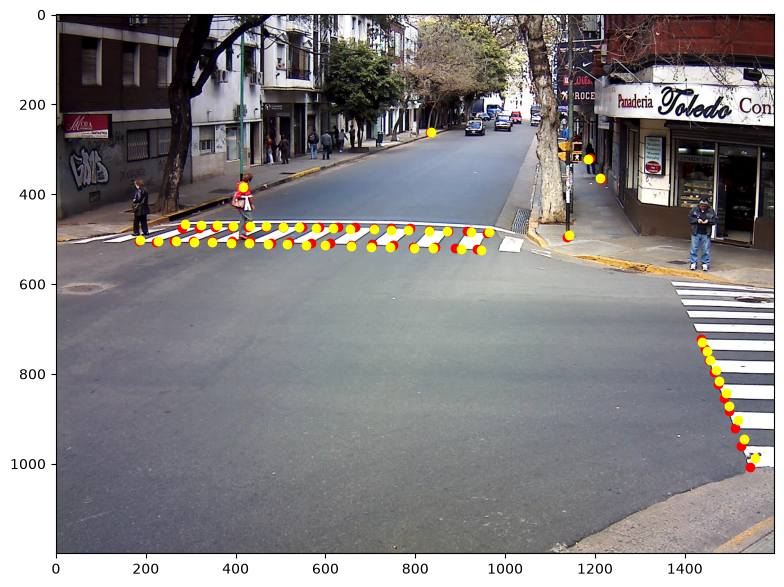

In [16]:
# b)

point_correspondences = np.loadtxt(buscar_ruta("salguero", "gs_10_09_point_correspondences_v5.txt"))
point_correspondences = np.array(point_correspondences)

matriz_puntos_t = trasponer(point_correspondences)

objPts_señora = np.zeros((51,2))
imgPts_señora = np.zeros((51,2))

for i in range(np.shape(matriz_puntos_t)[0]):
    objPts_señora[i][0] = matriz_puntos_t[i][1]
    objPts_señora[i][1] = matriz_puntos_t[i][2]
    imgPts_señora[i][0] = matriz_puntos_t[i][4]
    imgPts_señora[i][1] = matriz_puntos_t[i][5]

Q_señora = obtenerQ2d(imgPts_señora, objPts_señora)
H_señora = obtener_H(Q_señora)
R_señora, t_señora = obtenerPose2D(H_señora, K_salguero)

print("Pose de la cámara")
print("R",R_señora)
print("t",t_señora)

R_t_salguero = np.hstack((R_señora,t_señora.reshape(3,1)))
H_reproyectar = multiplicar_matrices(K_salguero, R_t_salguero)

ptos_reproyectados = []

for pto in objPts_señora:
    pto = np.array([pto[0],pto[1],0,1])
    pto_aux = calcularAx(H_reproyectar, pto)
    pto_reproyectado = pto_aux/pto_aux[2]
    ptos_reproyectados += [pto_reproyectado]

ptos_reproyectados = np.array(ptos_reproyectados)

# graficamos para ver que coincidan los puntos
img = cv2.imread(buscar_ruta("salguero", "img_10_18_47_351.jpg"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

plt.scatter(matriz_puntos_t[:, 4], matriz_puntos_t[:,5],c='r')
plt.scatter(ptos_reproyectados[:,0],ptos_reproyectados[:,1],c='yellow') 
plt.show()

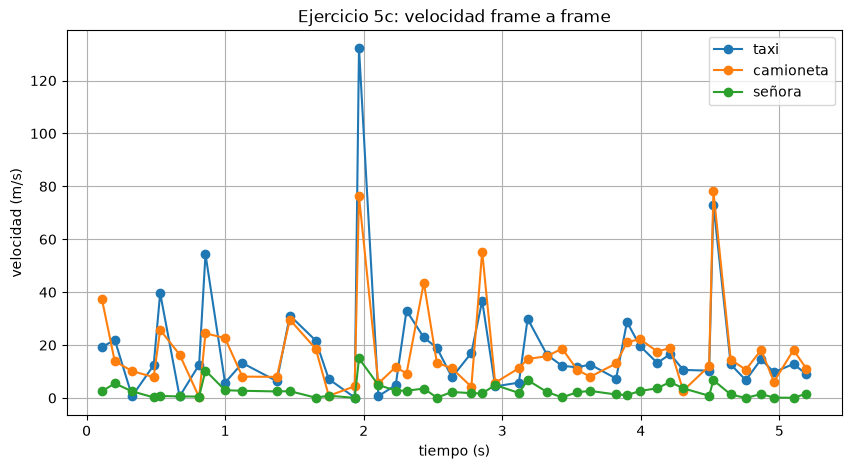

taxi 13.66312816665625 m/s = 49.1872613999625 km/h
camioneta 14.687864668761247 m/s = 52.87631280754049 km/h
señora 1.3043758133825876 m/s = 4.695752928177315 km/h


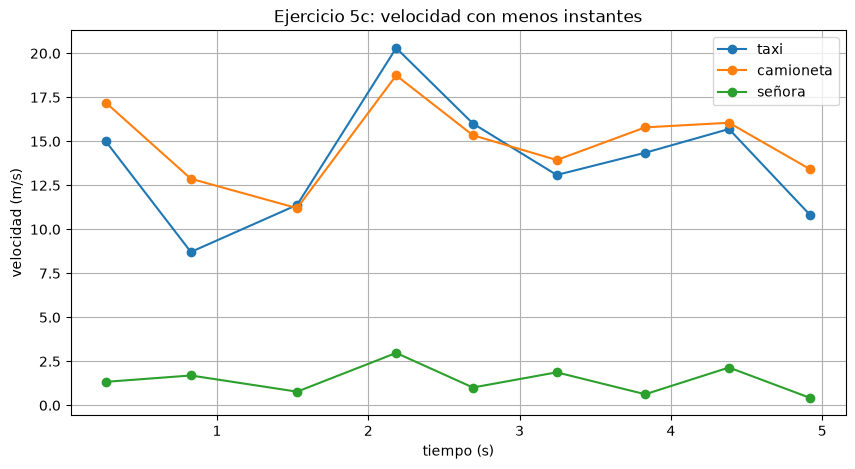

In [17]:
# c) 
clicks = np.loadtxt(buscar_ruta("clicks.csv"))

# Pasamos a segundos los instantes de cada foto en el tiempo para calcular la velocidad (van de 0 a 5 seg)

instantes_a_seg = np.array([0.0, 0.11, 0.203, 0.328, 0.484, 0.531, 0.671, 0.812, 0.858, 0.999, 1.124,
                            1.373, 1.467, 1.654, 1.748, 1.935, 1.966, 2.106, 2.231, 2.309, 2.434, 2.528,
                            2.637, 2.777, 2.855, 2.949, 3.12, 3.183, 3.323, 3.432, 3.542, 3.635, 3.822,
                            3.9, 3.994, 4.119, 4.212, 4.306, 4.493, 4.524, 4.649, 4.758, 4.868, 4.961, 5.102, 5.195])


#Usamos H
H_inv_señora = inversa(H_señora)
posiciones_señora = np.zeros((46,3,2)) #incluye taxi y camioneta

for k in range(46):
    for obj in range(3):
        pto_aux = np.array([clicks[k][2*obj], clicks[k][2*obj+1], 1.0])
        pos_señora_aux = calcularAx(H_inv_señora, pto_aux)

        posiciones_señora[k][obj] = np.array([pos_señora_aux[0]/pos_señora_aux[2],pos_señora_aux[1]/pos_señora_aux[2]])


# Hacemos la cuenta de velocidades
velocidades_taxi = []
velocidades_camioneta = []
velocidades_señora = []

for k in range(45): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+1][2][0] - posiciones_señora[k][2][0]
    delta_y = posiciones_señora[k+1][2][1] - posiciones_señora[k][2][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_señora.append(distancia/(instantes_a_seg[k+1] - instantes_a_seg[k]))


for k in range(45): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+1][1][0] - posiciones_señora[k][1][0]
    delta_y = posiciones_señora[k+1][1][1] - posiciones_señora[k][1][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_camioneta.append(distancia/(instantes_a_seg[k+1] - instantes_a_seg[k]))

for k in range(45): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+1][0][0] - posiciones_señora[k][0][0]
    delta_y = posiciones_señora[k+1][0][1] - posiciones_señora[k][0][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_taxi.append(distancia/(instantes_a_seg[k+1] - instantes_a_seg[k]))

plt.figure(figsize=(10, 5))
plt.plot(instantes_a_seg[1:], velocidades_taxi, marker='o', label="taxi")
plt.plot(instantes_a_seg[1:], velocidades_camioneta, marker='o', label="camioneta")
plt.plot(instantes_a_seg[1:], velocidades_señora, marker='o', label="señora")
plt.xlabel("tiempo (s)")
plt.ylabel("velocidad (m/s)")
plt.title("Ejercicio 5c: velocidad frame a frame")
plt.legend()
plt.grid(True)
plt.show()

for o, nombre in [(0, "taxi"), (1, "camioneta"), (2, "señora")]:
    dx = posiciones_señora[-1][o][0] - posiciones_señora[0][o][0]
    dy = posiciones_señora[-1][o][1] - posiciones_señora[0][o][1]
    distancia = np.sqrt(dx**2 + dy**2)
    tiempo_total = instantes_a_seg[-1] - instantes_a_seg[0]
    v = distancia / tiempo_total
    print(nombre, v, "m/s =", 3.6*v, "km/h")

# Si usamos todos los frames queda mucho ruido y es dificil visualizar bien las velocidades
# Lo volvemos a hacer con menos frames

velocidades_taxi_recorte = []
velocidades_camioneta_recorte = []
velocidades_señora_recorte = []

for k in range(0,41,5): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+5][2][0] - posiciones_señora[k][2][0]
    delta_y = posiciones_señora[k+5][2][1] - posiciones_señora[k][2][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_señora_recorte.append(distancia/(instantes_a_seg[k+5] - instantes_a_seg[k]))


for k in range(0,41,5): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+5][1][0] - posiciones_señora[k][1][0]
    delta_y = posiciones_señora[k+5][1][1] - posiciones_señora[k][1][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_camioneta_recorte.append(distancia/(instantes_a_seg[k+5] - instantes_a_seg[k]))

for k in range(0,41,5): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+5][0][0] - posiciones_señora[k][0][0]
    delta_y = posiciones_señora[k+5][0][1] - posiciones_señora[k][0][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_taxi_recorte.append(distancia/(instantes_a_seg[k+5] - instantes_a_seg[k]))

t_recorte = []
for r in range(0,41,5):
    t_recorte.append((instantes_a_seg[r] + instantes_a_seg[r+5])/2)



plt.figure(figsize=(10, 5))
plt.plot(t_recorte, velocidades_taxi_recorte, marker='o', label="taxi")
plt.plot(t_recorte, velocidades_camioneta_recorte, marker='o', label="camioneta")
plt.plot(t_recorte, velocidades_señora_recorte, marker='o', label="señora")
plt.xlabel("tiempo (s)")
plt.ylabel("velocidad (m/s)")
plt.title("Ejercicio 5c: velocidad con menos instantes")
plt.legend()
plt.grid(True)
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

Pose de la cámara
[[-0.11458951 -0.98679844 -0.11444689]
 [-0.96401698  0.13827664 -0.22704807]
 [ 0.23987601  0.08431142 -0.9671355 ]] [-0.71757552  0.8885919   4.37455297]


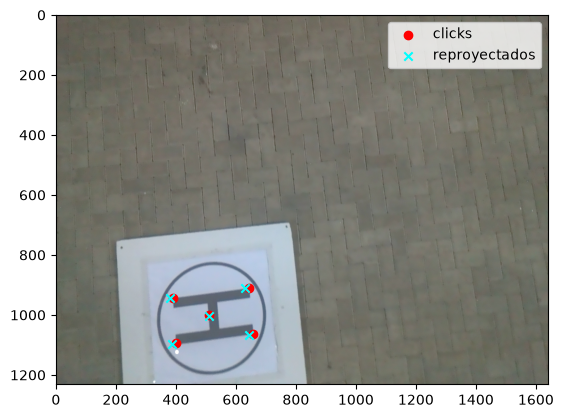

In [18]:
K_heli = np.array([[1892.9,0.0,819.5],
          [0.0,1909.5,615.5],
          [0.0,0.0,1.0]])

imgPtos_heli = np.array([[ 509.0, 1000.0],
                [ 401.0, 1095.0],
                [ 391.0,  943.0],
                [ 643.0,  909.0],
                [ 657.0, 1063.0]])

objPtos_heli = np.array([[ 0.0,    0.0,    0.0  ],
                [-0.175,  0.3,    0.0  ],
                [ 0.175,  0.3,    0.0  ],
                [ 0.175, -0.3,    0.0  ],
                [-0.175, -0.3,    0.0  ]])

R_heli, t_heli = aplicarPOSIT(objPtos_heli, imgPtos_heli, K_heli, 50, 1e-6)

print("Pose de la cámara")
print(R_heli, t_heli)

#Graficamos los puntos sobre la imagen

import cv2
rvec, _ = cv2.Rodrigues(R_heli)
proy, _ = cv2.projectPoints(objPtos_heli, rvec, t_heli, K_heli, None)


img = cv2.imread(buscar_ruta("heli", "row_00248.png"))
plt.imshow(img[:, :, ::-1])
plt.scatter(imgPtos_heli[:, 0], imgPtos_heli[:, 1], c="red", label="clicks")
plt.scatter(proy[:, 0, 0], proy[:, 0, 1], c="cyan", marker="x", label="reproyectados")
plt.legend(); plt.show()

---